# M05 | NHS A&E longitudinal preparation

**Research objective:** establish a consistent monthly reporting calendar for each provider and define a provisional, time-aware population for next-month Type 1 attendance forecasting.

**Source:** [NHS A&E IDSS repository](https://github.com/neoscar10/NHS-A-E-IDSS), verified M04 provider and national outputs.

**Research question:** how can we distinguish absence from reported zero activity, examine continuity, and define a forecasting population without using future outcomes?

Run all cells in sequence to generate the analysis, figures and evidence snapshot.

## 1. Methodology and parameters

Each provider enters the calendar in its first observed month. Subsequent months without a record are marked absent, even after its last observation. No counts or provider attributes are filled. These calendar rows are analytical placeholders, not NHS submissions.

The eligibility rule is provisional: the provider must have an observation at the origin, 12 consecutive observed months through the origin, and at least one positive Type 1 value within that window. This is a proxy for recent activity, not verified service classification. A 12-month window supports evaluating a seasonal baseline. The rule is fixed for this analysis and can be evaluated for sensitivity using training data only.

The origin means the latest available reporting month. The actual publication date and data availability must be considered before building forecasting features.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
import pandas as pd

repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/data/m05_longitudinal.py").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Open the NHS-A-E-IDSS repository in VS Code.")
sys.path.insert(0, str(repo_root))
from src.data.m05_longitudinal import run_longitudinal, TARGET, STATUSES

M04_RUN_ID = None  # None selects the latest M04 run; specify its ID to reproduce a particular snapshot.
HISTORY_WINDOW = 12

## 2. Execute longitudinal preparation

The pipeline checks that the selected M04 run is complete and that the source output fingerprints match its recorded values. It checks row conservation, calendar uniqueness and preservation of reported counts. It then runs regression tests and exports a timestamped evidence snapshot.

In [2]:
result = run_longitudinal(repo_root, M04_RUN_ID, HISTORY_WINDOW, run_tests=True, notebook=True)
s = result["summary"]
panel, profile, monthly = (result[k] for k in ("panel", "profile", "monthly"))
evidence = Path(result["evidence_path"])
if result["evidence_status"] != "COMPLETE":
    raise RuntimeError("Evidence run requires review. Do not use partial outputs.")
display(Markdown(f"""### Results at a glance

| Measure | Result |
|---|---:|
| Reporting months | {s['reporting_months']:,} |
| Provider codes observed at least once | {s['provider_codes']:,} |
| Original provider-month records conserved | {s['observed_rows']:,} |
| Calendar rows, including absent records | {s['calendar_rows']:,} |
| Absent records | {s['absent_rows']:,} |
| Reported zero Type 1 observations | {s['reported_zero_rows']:,} |
| Provisional candidates in {s['latest_month']} | {s['latest_candidates']:,} / {s['latest_observed_providers']:,} reported providers |

**Pipeline outcome:** `{s['status']}`. This does not establish clinical equivalence of provider codes or model readiness."""))

### Results at a glance

| Measure | Result |
|---|---:|
| Reporting months | 57 |
| Provider codes observed at least once | 223 |
| Original provider-month records conserved | 11,392 |
| Calendar rows, including absent records | 12,263 |
| Absent records | 871 |
| Reported zero Type 1 observations | 4,426 |
| Provisional candidates in 2026-09 | 120 / 191 reported providers |

**Pipeline outcome:** `PASS_LONGITUDINAL_PREPARATION`. This does not establish clinical equivalence of provider codes or model readiness.

## 3. Reporting coverage and missing months

**Research question:** how stable is the reporting population after providers first appear?

**Method:** compare rows in the provider calendar with actual reported observations. The gap between the two series represents absent records, not zero attendances or confirmed service closures.

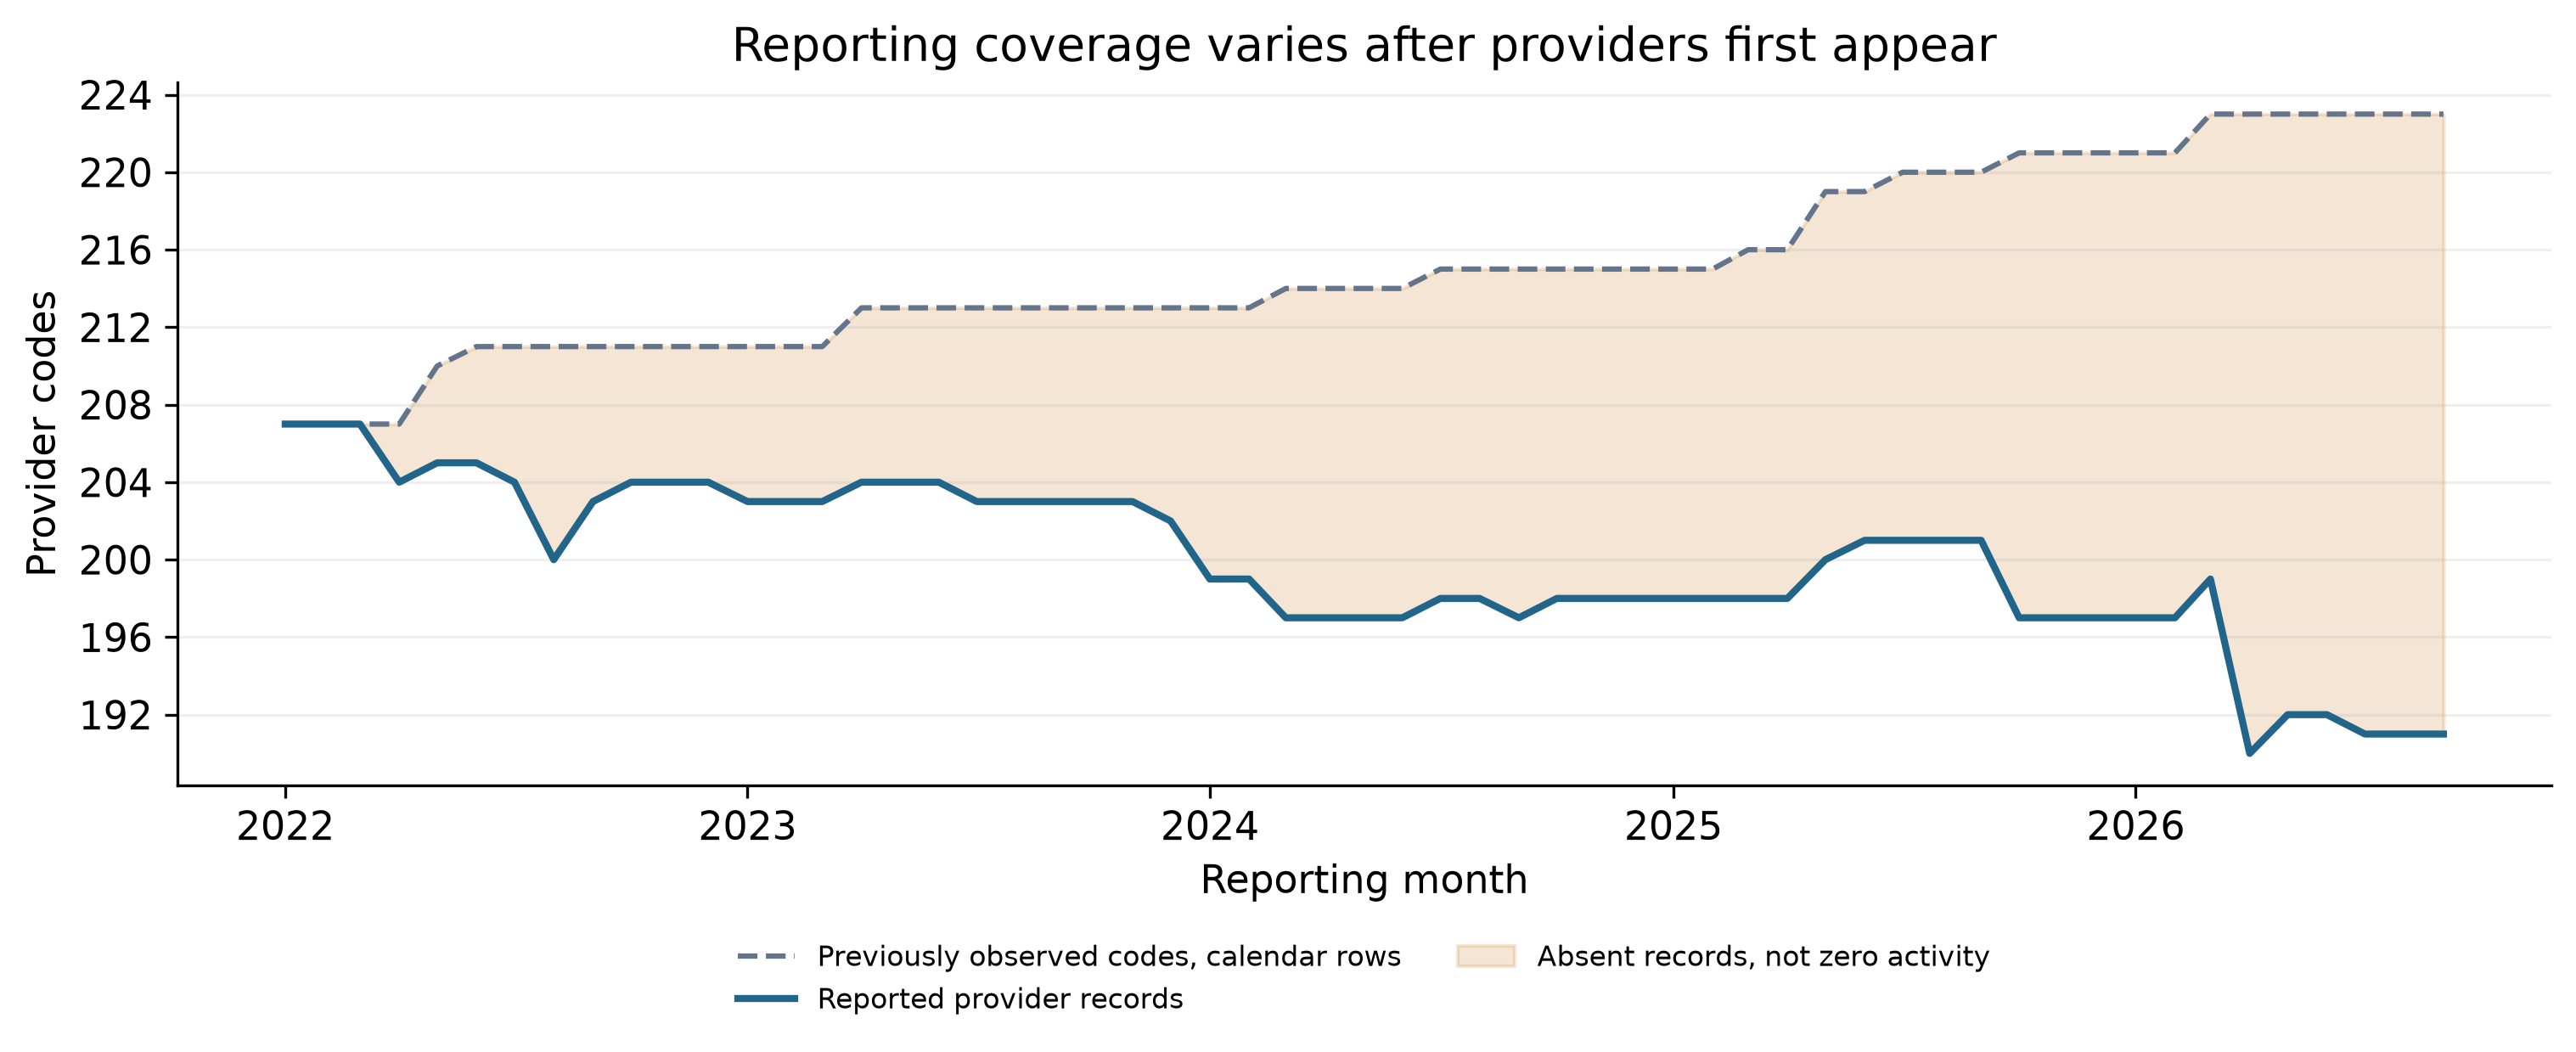

**Finding:** 11,392 reported records were retained. The calendar additionally identifies 871 absent records: 30 within observed spans and 841 after final observations.

**Interpretation:** reporting absence may reflect organisational changes, a service change or a reporting gap. The dataset alone does not establish the cause.

**Decision:** retain null counts for absent records. Never substitute zero or use the next available row as if it were the next calendar month.

In [3]:
display(Image(filename=str(evidence / "figures/01_reporting_coverage.png"), width=900))
display(Markdown(f"""**Finding:** {s['observed_rows']:,} reported records were retained. The calendar additionally identifies {s['absent_rows']:,} absent records: {s['internal_gap_rows']:,} within observed spans and {s['absent_after_last_observation_rows']:,} after final observations.

**Interpretation:** reporting absence may reflect organisational changes, a service change or a reporting gap. The dataset alone does not establish the cause.

**Decision:** retain null counts for absent records. Never substitute zero or use the next available row as if it were the next calendar month."""))

## 4. Provider continuity and identity

**Research question:** which codes have reporting gaps or variations in recorded names and parent groups?

**Method:** count internal gaps retrospectively within each provider's first and last observed month. Review recorded name and parent-group variants without assuming they imply mergers. This descriptive audit uses full history; it must not be used to select earlier model cohorts.

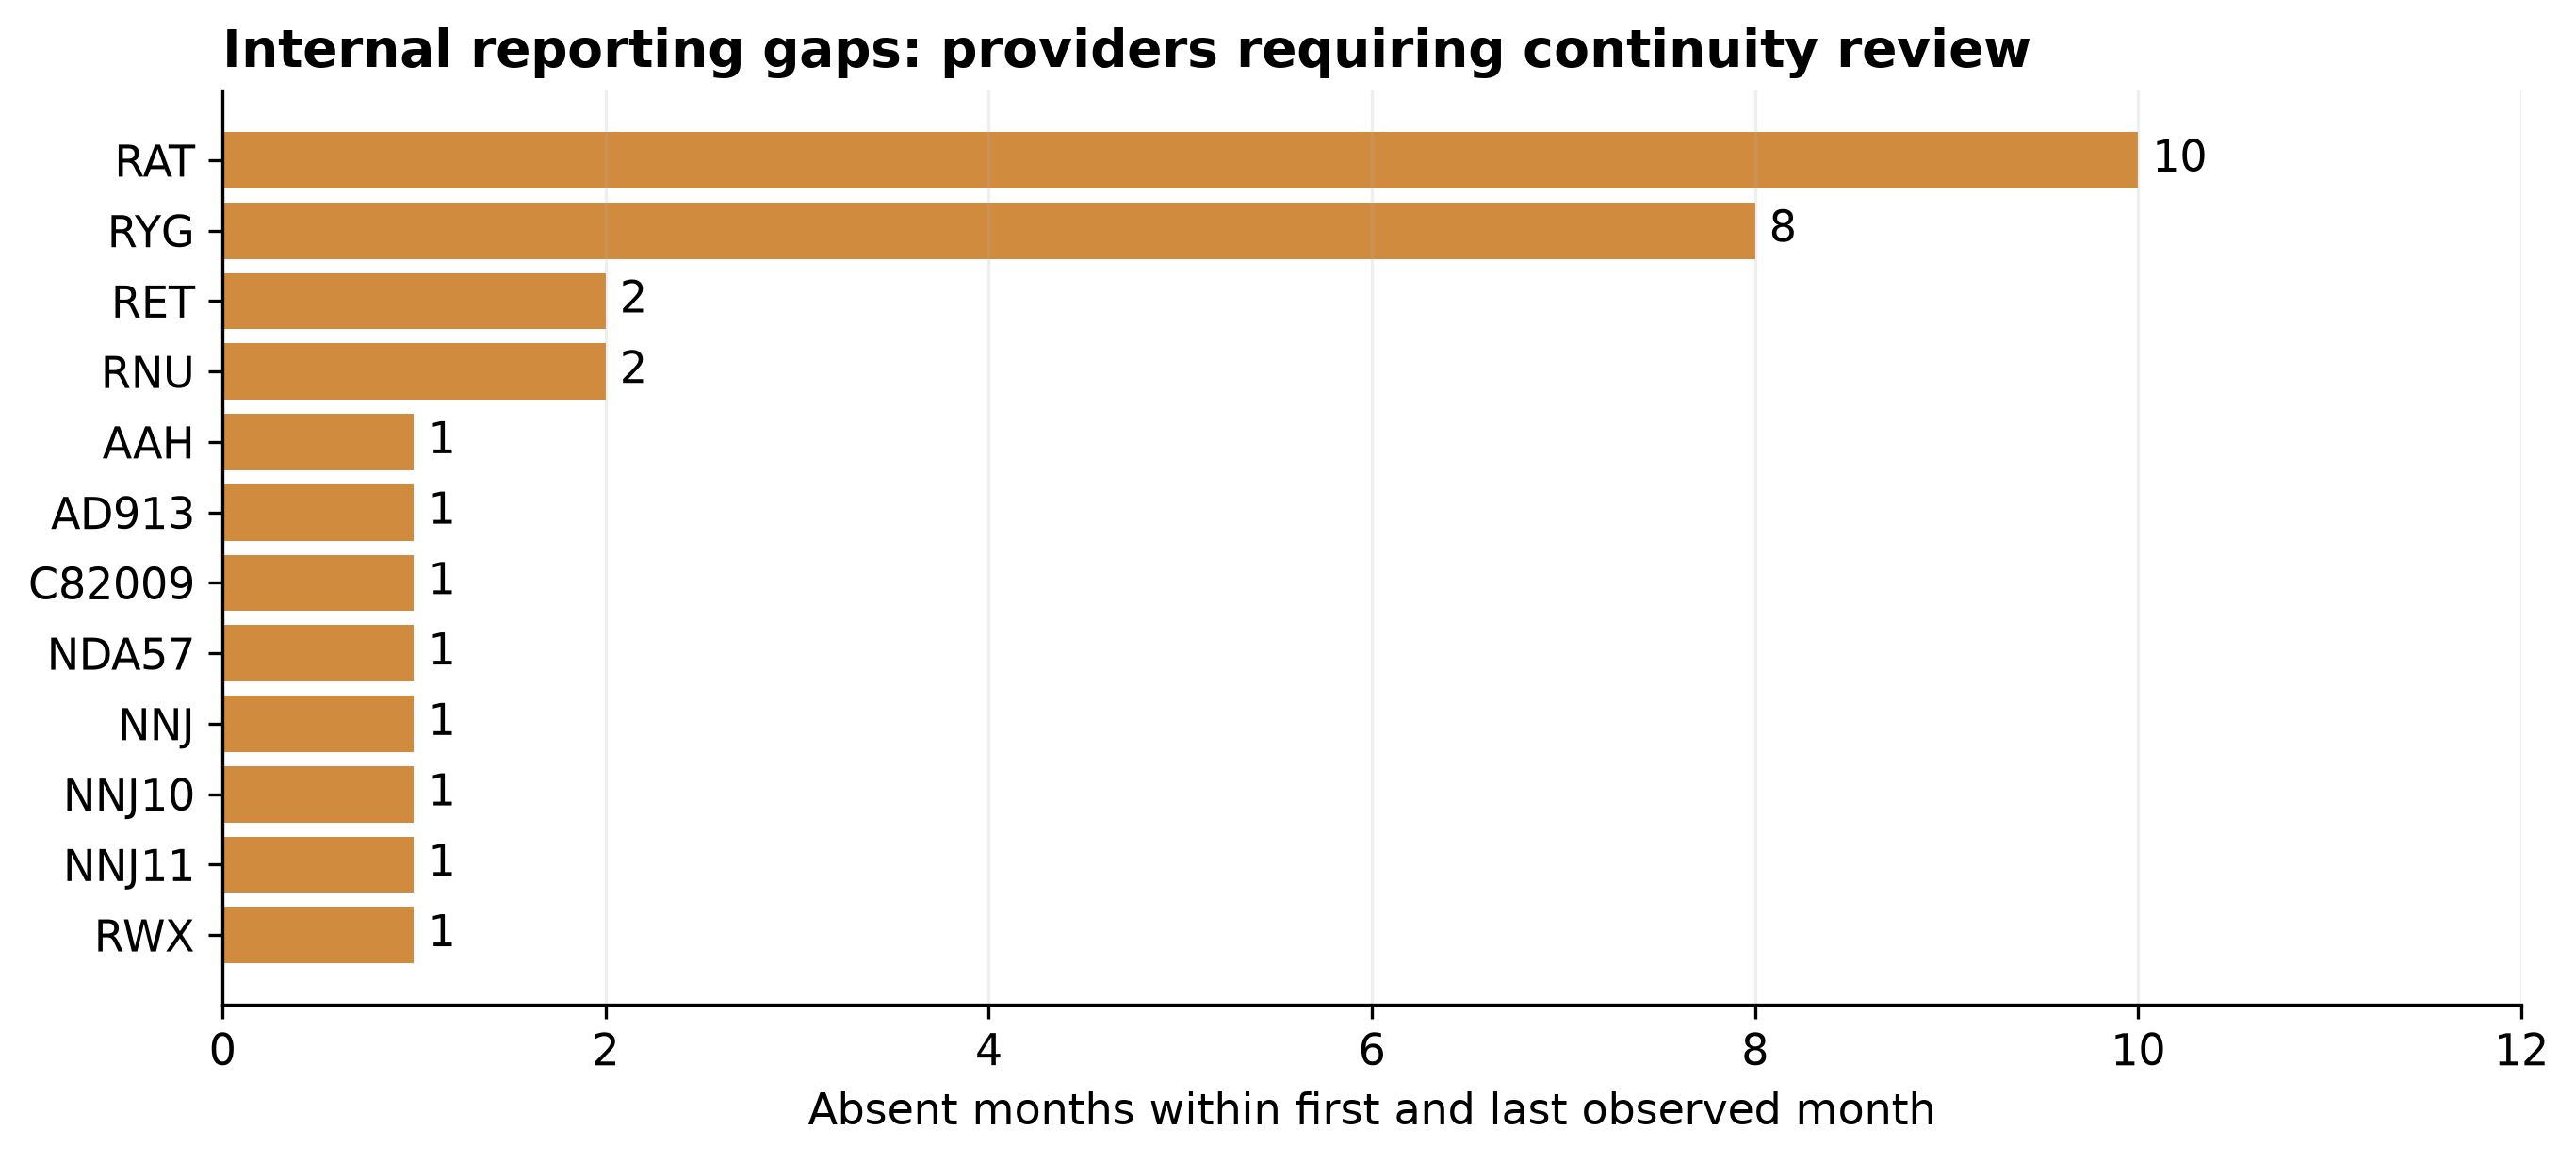

,org_code,first_observed_month,last_observed_month,observed_months,missing_within_observed_span,distinct_recorded_names,distinct_recorded_parent_groups
73,RAT,2022-01,2026-09,47,10,1,1
206,RYG,2022-01,2026-09,49,8,1,1
99,RET,2022-01,2026-09,55,2,1,1
144,RNU,2022-01,2026-09,55,2,1,1
2,AAH,2022-01,2026-09,56,1,1,1
5,AD913,2022-01,2026-09,56,1,1,1
11,C82009,2022-01,2026-09,56,1,1,1
24,NDA57,2022-01,2023-12,23,1,1,1
34,NNJ,2022-01,2026-09,56,1,1,1
37,NNJ10,2026-03,2026-09,6,1,1,1


**Finding:** 12 codes have internal gaps; 18 have recorded name variants and 0 have parent-group variants.

**Decision:** investigate relevant identities using historical NHS organisation and service information. Do not merge or discard records based solely on name variation. Retain the M03 change advisories for source-based review.

In [4]:
display(Image(filename=str(evidence / "figures/03_provider_gap_review.png"), width=860))
review = profile.loc[(profile.missing_within_observed_span > 0) | (profile.distinct_recorded_names > 1) | (profile.distinct_recorded_parent_groups > 1)]
display(review.sort_values(["missing_within_observed_span", "org_code"], ascending=[False, True]).head(12)[["org_code", "first_observed_month", "last_observed_month", "observed_months", "missing_within_observed_span", "distinct_recorded_names", "distinct_recorded_parent_groups"]])
display(Markdown(f"""**Finding:** {s['providers_with_internal_gaps']:,} codes have internal gaps; {s['providers_with_name_variants']:,} have recorded name variants and {s['providers_with_parent_variants']:,} have parent-group variants.

**Decision:** investigate relevant identities using historical NHS organisation and service information. Do not merge or discard records based solely on name variation. Retain the M03 change advisories for source-based review."""))

## 5. Time-aware forecasting eligibility

**Research question:** which provider-month origins have sufficient recent observations to support a next-month forecast?

**Method:** rolling calendar windows use observed records through the origin, including the origin itself. Candidate status does not use the next-month outcome. A provider may be a candidate even when its origin value is zero if the preceding window contains positive activity. A provider with a missing month is not eligible until the required consecutive history is re-established.

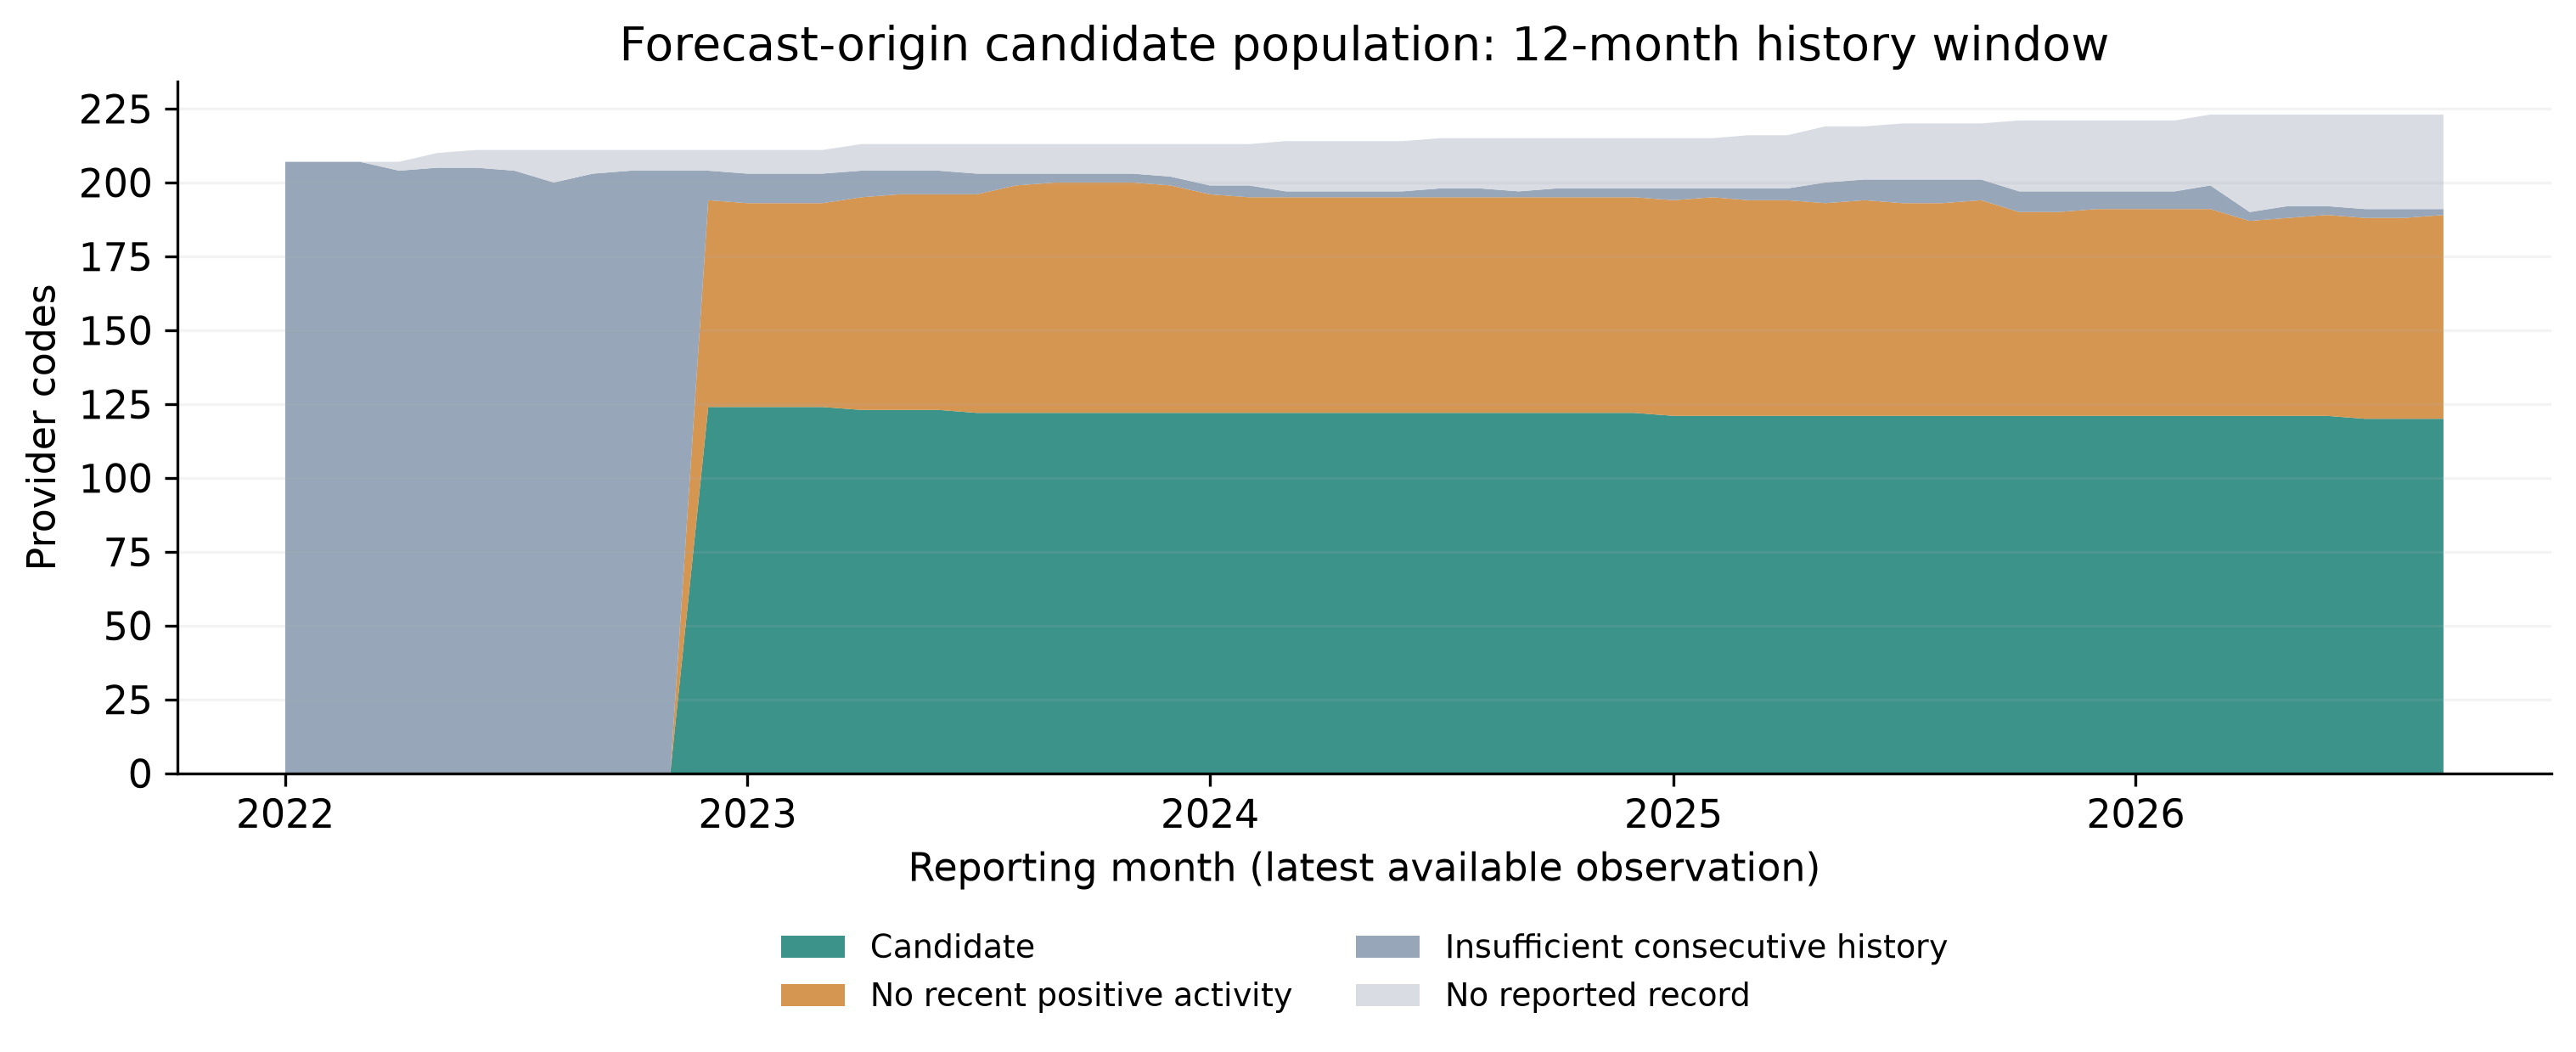

,Status,Provider codes
0,Candidate,120
1,No recent positive activity,69
2,Insufficient consecutive history,2
3,No reported record,32


**Finding:** at the latest reporting month (2026-09), 120 of 191 reported providers meet the provisional candidate rule. The 5,599 candidate origins across the history are not the number of usable training pairs.

**Decision:** preserve all observations and evaluate seasonal-naive and regression models on comparable, time-aware cohorts. At model evaluation, require a real next-month target, never a filled value. Verify source publication timing before assuming a reporting month was available at an origin.

In [5]:
display(Image(filename=str(evidence / "figures/02_time_aware_candidates.png"), width=900))
latest = monthly.iloc[-1]
status_table = pd.DataFrame({"Status": STATUSES, "Provider codes": [int(latest[k]) for k in STATUSES]})
display(status_table)
display(Markdown(f"""**Finding:** at the latest reporting month ({s['latest_month']}), {s['latest_candidates']:,} of {s['latest_observed_providers']:,} reported providers meet the provisional candidate rule. The {s['candidate_origin_rows']:,} candidate origins across the history are not the number of usable training pairs.

**Decision:** preserve all observations and evaluate seasonal-naive and regression models on comparable, time-aware cohorts. At model evaluation, require a real next-month target, never a filled value. Verify source publication timing before assuming a reporting month was available at an origin."""))

## 6. Decision register and evidence

The register distinguishes implemented data transformations from assumptions and outstanding source reviews. M06 will establish the final analytical data contract before M07 creates features.

In [6]:
display(result["decisions"])
print("Processed outputs:")
for path in s["outputs"]:
    print(path)
print("Evidence:", evidence.relative_to(repo_root))
print("Manifest status:", result["evidence_status"])

,finding,decision,status
0,Absent provider-month,Keep measures null; no imputation or inferred ...,Implemented
1,Reported zeros,Retain exactly as published,Implemented
2,Name and parent variants,Flag for source-based identity review; no merging,Review required where flagged
3,Candidate eligibility,"Observed at origin, full history window, at le...",Provisional operational rule
4,Candidate status,Use only observations at or before origin; nev...,Implemented
5,Publication timing,Confirm availability at each forecast origin b...,M07
6,Actual Type 1 service status,Validate against authoritative organisation/se...,Open limitation
7,Outliers,Retain observed values; inspect M03 change can...,Review required where flagged


Processed outputs:
data/processed/m05/20261117T234951Z_969acc23/ae_provider_calendar.csv
data/processed/m05/20261117T234951Z_969acc23/ae_provider_calendar.parquet
Evidence: docs\evidence\M05_Longitudinal_Preparation\20261117T234951Z_969acc23
Manifest status: COMPLETE
